In [1]:
%pip install -q torchmetrics
%pip install -q ultralytics

In [2]:
from ultralytics import YOLO
from torch.utils.data import DataLoader, TensorDataset, random_split
from torchvision import datasets, transforms
from pathlib import Path
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
from PIL import Image
from pathlib import Path
from datasets import load_dataset
import csv
import yaml
import time
import pandas as pd
from torchmetrics.classification import MulticlassJaccardIndex, MulticlassConfusionMatrix, MulticlassF1Score
import matplotlib.pyplot as plt
import cv2

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [3]:
SEED = 51
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
BATCH_SIZE = 8
torch.manual_seed(SEED)
DEVICE

'cuda'

In [4]:
DATASET_ID = "nikolkoo/SatelliteSegmentation"
ROOT = Path.home() / "data" / "SatelliteSegmentation"
IMAGE_DIR = ROOT / "images"
MASK_DIR = ROOT / "masks"
IMAGE_DIR.mkdir(parents=True, exist_ok=True)
MASK_DIR.mkdir(parents=True, exist_ok=True)


# Descargar dataset

print("Conectando con Hugging Face")
ds = load_dataset(DATASET_ID, split="train")
print(f"\nImágenes encontradas: {len(ds)}")
print(f"Columnas: {ds.column_names}")


# Descargar imágenes y máscaras
manifest = []
for i, sample in enumerate(ds):
    image = sample["image"]
    mask = sample["mask"]

    image_name = f"{i:04d}.png"
    mask_name = f"{i:04d}_mask.png"

    image_path = IMAGE_DIR / image_name
    mask_path = MASK_DIR / mask_name
    image.convert("RGB").save(image_path)

    # Conservar los valores originales de las etiquetas
    mask.save(mask_path)

    manifest.append({
        "id": i,
        "image": image_name,
        "mask": mask_name,
        "width": image.width,
        "height": image.height,
        "mask_mode": mask.mode
    })
    if (i + 1) % 100 == 0:
        print(f"Descargadas: {i + 1}/{len(ds)}")


# Guardar manifiesto
with open(ROOT / "manifest.csv", "w", newline="") as file:
    writer = csv.DictWriter(
        file,
        fieldnames=manifest[0].keys()
    )
    writer.writeheader()
    writer.writerows(manifest)


print("\nDescarga completada.")
print(f"Imágenes: {len(list(IMAGE_DIR.glob('*.png')))}")
print(f"Máscaras: {len(list(MASK_DIR.glob('*.png')))}")
print(f"Directorio: {ROOT}")

Conectando con Hugging Face


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


README.md:   0%|          | 0.00/2.24k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 93.6MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/790 [00:00<?, ? examples/s]


Imágenes encontradas: 790
Columnas: ['image', 'mask']
Descargadas: 100/790
Descargadas: 200/790
Descargadas: 300/790
Descargadas: 400/790
Descargadas: 500/790
Descargadas: 600/790
Descargadas: 700/790

Descarga completada.
Imágenes: 790
Máscaras: 790
Directorio: /root/data/SatelliteSegmentation


In [5]:
MASK_DIR = Path.home() / "data" / "SatelliteSegmentation" / "masks"
IMAGE_DIR = Path.home() / "data" / "SatelliteSegmentation" / "images"

print("Imágenes encontradas:", len(list(IMAGE_DIR.glob("*.png"))))
print("Máscaras encontradas:", len(list(MASK_DIR.glob("*.png"))))

Imágenes encontradas: 790
Máscaras encontradas: 790


In [6]:
#Se tiene que corregir las etiquetas de las clases

class_names = {
    0: "Sin etiqueta",
    10: "Árboles",
    20: "Matorrales",
    30: "Pastizales",
    40: "Cultivos",
    50: "Zonas construidas",
    60: "Suelo desnudo / vegetación escasa",
    70: "Nieve y hielo",
    80: "Cuerpos de agua",
    90: "Humedales",
    95: "Manglares",
    100: "Musgos y líquenes"
}

label_mapping = {
    0: 255,
    10: 0,
    20: 1,
    30: 2,
    40: 3,
    50: 4,
    60: 5,
    70: 6,
    80: 7,
    90: 8,
    95: 9,
    100: 10
}

image_files = sorted(IMAGE_DIR.glob("*.png"))
mask_files = sorted(MASK_DIR.glob("*_mask.png"))

images_by_name = {f.stem: f for f in image_files}
masks_by_name = {
    f.stem.replace("_mask", ""): f
    for f in mask_files
}

common_names = sorted(set(images_by_name) & set(masks_by_name))

print("Imágenes:", len(image_files))
print("Máscaras:", len(mask_files))
print("Pares encontrados:", len(common_names))

model_class_names = {
    label_mapping[original]: name
    for original, name in class_names.items()
    if original != 0}

Imágenes: 790
Máscaras: 790
Pares encontrados: 790


In [7]:
images = []
masks = []

for name in common_names:
    image = Image.open(images_by_name[name]).convert("RGB")
    image = np.array(image, dtype=np.float32) / 255.0
    mask = np.array(Image.open(masks_by_name[name]))

    mapped_mask = np.full(mask.shape, 255, dtype=np.uint8)

    for original, mapped in label_mapping.items():
        mapped_mask[mask == original] = mapped

    images.append(torch.from_numpy(image).permute(2,0,1))
    masks.append(torch.from_numpy(mapped_mask.astype(np.int64)))

X = torch.stack(images)
Y = torch.stack(masks)


print("Dimensiones de imágenes:", X.shape)
print("Dimensiones de máscaras:", Y.shape)
print("Tipo de imágenes:", X.dtype)
print("Tipo de máscaras:", Y.dtype)   

Dimensiones de imágenes: torch.Size([790, 3, 256, 256])
Dimensiones de máscaras: torch.Size([790, 256, 256])
Tipo de imágenes: torch.float32
Tipo de máscaras: torch.int64


In [8]:
dataset = TensorDataset(X,Y)

#Qué hueva descargar test_train_split

train_size = int(len(dataset) * 0.70)
val_size = int(len(dataset) * 0.15)

test_size = len(dataset) - (train_size + val_size)

print(train_size)
print(test_size)
print(val_size)

553
119
118


In [9]:
#Generador para el DataLoader
generator = torch.Generator()
generator.manual_seed(SEED)

train_set, val_set, test_set = random_split(
    dataset, [train_size, val_size, test_size],
    generator=generator
)

train_loader = DataLoader(
    train_set,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    generator=generator
)

val_loader = DataLoader(
    val_set,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    generator=generator
)

test_loader = DataLoader(
    test_set,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    generator=generator
)


print(f"\nBatches de entrenamiento: {len(train_loader)}")
print(f"Batches de validación:    {len(val_loader)}")
print(f"Batches de prueba:        {len(test_loader)}")


Batches de entrenamiento: 70
Batches de validación:    15
Batches de prueba:        15


In [10]:
YOLO_DATA_DIR = Path.home() / "data" / "SatelliteSegmentation_YOLO"

for split in ["train", "val"]:
    (YOLO_DATA_DIR / "images" / split).mkdir(parents=True, exist_ok=True)
    (YOLO_DATA_DIR / "masks" / split).mkdir(parents=True, exist_ok=True)

splits = {
    "train": train_set.indices,
    "val": val_set.indices
}

for split, indices in splits.items():

    for idx in indices:
        name = common_names[idx]
        image_path = IMAGE_DIR / f"{name}.png"
        mask_path = YOLO_DATA_DIR / "masks" / split / f"{name}.png"
        output_image = YOLO_DATA_DIR / "images" / split / f"{name}.png"
        Image.open(image_path).convert("RGB").save(output_image)

        mask = Y[idx].cpu().numpy().astype(np.uint8)
        Image.fromarray(mask).save(mask_path)

data_config = {
    "path": str(YOLO_DATA_DIR),
    "train": "images/train",
    "val": "images/val",
    "masks_dir": "masks",
    "names": model_class_names
}

with open(YOLO_DATA_DIR / "dataset.yaml", "w") as f:
    yaml.safe_dump(data_config, f, sort_keys=False, allow_unicode=True)

In [11]:
#Esta es la U-NEt que voy a usar
class BloqueDobleConv(nn.Module):
    """(Conv2d -> BatchNorm -> ReLU) * 2"""
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )
    def forward(self, x):
        return self.net(x)

class UNetCompacta(nn.Module):
    def __init__(self, in_channels=3, num_classes=3):
        super().__init__()
        # --- ENCODER ---
        self.enc1 = BloqueDobleConv(in_channels, 32)      # Entrada: 128x128
        self.pool1 = nn.MaxPool2d(2, 2)                   # -> 64x64

        self.enc2 = BloqueDobleConv(32, 64)               # -> 64x64
        self.pool2 = nn.MaxPool2d(2, 2)                   # -> 32x32

        self.enc3 = BloqueDobleConv(64, 128)              # -> 32x32
        self.pool3 = nn.MaxPool2d(2, 2)                   # -> 16x16

        # --- BOTTLENECK ---
        self.bottleneck = BloqueDobleConv(128, 256)       # -> 16x16

        # --- DECODER & SKIP CONNECTIONS ---
        self.up3 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2) # -> 32x32
        self.dec3 = BloqueDobleConv(256, 128)             # 128 (skip) + 128 = 256

        self.up2 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)   # -> 64x64
        self.dec2 = BloqueDobleConv(128, 64)              # 64 (skip) + 64 = 128

        self.up1 = nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2)    # -> 128x128
        self.dec1 = BloqueDobleConv(64, 32)               # 32 (skip) + 32 = 64

        # Proyección final lineal a nivel de píxel
        self.out_conv = nn.Conv2d(32, num_classes, kernel_size=1)

    def forward(self, x):
        # Paso por el Encoder
        s1 = self.enc1(x)
        p1 = self.pool1(s1)

        s2 = self.enc2(p1)
        p2 = self.pool2(s2)

        s3 = self.enc3(p2)
        p3 = self.pool3(s3)

        # Cuello de botella
        b = self.bottleneck(p3)

        # Paso por el Decoder con Skip Connections (torch.cat)
        d3 = self.up3(b)
        d3 = torch.cat([d3, s3], dim=1)
        d3 = self.dec3(d3)

        d2 = self.up2(d3)
        d2 = torch.cat([d2, s2], dim=1)
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1 = torch.cat([d1, s1], dim=1)
        d1 = self.dec1(d1)

        return self.out_conv(d1)

modelo = UNetCompacta(in_channels=3, num_classes=11).to(DEVICE)
print("Arquitectura instanciada. Parámetros totales:", sum(p.numel() for p in modelo.parameters()))

Arquitectura instanciada. Parámetros totales: 1927339


In [12]:
#Este es el modelo de YOLO
model_yolo = YOLO("yolo26n-sem.pt")
model_yolo.info()

YOLO26n-sem summary: 133 layers, 1,632,902 parameters, 0 gradients, 4.5 GFLOPs


(133, 1632902, 0, 4.5007872)

In [13]:
optimizador = torch.optim.Adam(modelo.parameters(), lr=0.0001)
loss_fun = nn.CrossEntropyLoss(ignore_index=255) #No queremos meter los pixeles vacíos

In [14]:
EPOCHS = 15
epochs_list = []
train_loss_list = []
val_loss_list = []
train_iou_list = []
val_iou_list = []
train_dice_list = []
val_dice_list = []

In [15]:
#Métricas que voy a usar
metric_iou = MulticlassJaccardIndex(num_classes=11, average="macro", ignore_index=255).to(DEVICE)
metric_dice = MulticlassF1Score(num_classes=11, average="macro", ignore_index=255).to(DEVICE)

In [16]:
for epoch in range(EPOCHS):
    inicio = time.time()
    train_loss = 0.0
    metric_dice.reset()
    metric_iou.reset()

    modelo.train()
    for images, masks in train_loader:
        images = images.to(DEVICE)
        masks = masks.to(DEVICE)

        optimizador.zero_grad()
        outputs = modelo(images)
        loss = loss_fun(outputs, masks)
        loss.backward()
        optimizador.step()
        train_loss += loss.item()
        preds = torch.argmax(outputs.detach(), dim=1) #¿Para qué es esto?
        metric_iou.update(preds, masks)
        metric_dice.update(preds, masks)

    train_loss /= len(train_loader)
    train_dice = metric_dice.compute().item()
    train_iou = metric_iou.compute().item()

    modelo.eval()
    val_loss = 0.0
    metric_dice.reset()
    metric_iou.reset()

    with torch.no_grad():
        for images, masks in val_loader:
            images = images.to(DEVICE)
            masks = masks.to(DEVICE)

            outputs = modelo(images)
            loss = loss_fun(outputs, masks)
            val_loss += loss.item()
            preds = torch.argmax(outputs, dim=1)
            metric_iou.update(preds, masks)
            metric_dice.update(preds, masks)

    val_loss /= len(val_loader)
    val_iou = metric_iou.compute().item()
    val_dice = metric_dice.compute().item()

    epochs_list.append(epoch+1)
    train_loss_list.append(train_loss)
    val_loss_list.append(val_loss)

    train_iou_list.append(train_iou)
    val_iou_list.append(val_iou)
    train_dice_list.append(train_dice)
    val_dice_list.append(val_dice)

    tiempo_final = time.time() - inicio
    print(f"Tiempo: {tiempo_final} s")
    print(f"Época: {epoch+1} / {EPOCHS} | Train Loss: {train_loss:.4f} | Val loss: {val_loss:.4f}")
    print(f"Train IoU: {train_iou:.4f} | Val IoU: {val_iou:.4f} | Train Dice: {train_dice:.4f} | Val Dice: {val_dice:.4f}")

Tiempo: 12.834381341934204 s
Época: 1 / 15 | Train Loss: 1.9093 | Val loss: 1.6412
Train IoU: 0.1371 | Val IoU: 0.1863 | Train Dice: 0.1889 | Val Dice: 0.2377
Tiempo: 11.149020433425903 s
Época: 2 / 15 | Train Loss: 1.5442 | Val loss: 1.5237
Train IoU: 0.1888 | Val IoU: 0.1960 | Train Dice: 0.2499 | Val Dice: 0.2539
Tiempo: 11.279958009719849 s
Época: 3 / 15 | Train Loss: 1.3596 | Val loss: 1.3111
Train IoU: 0.2153 | Val IoU: 0.2349 | Train Dice: 0.2782 | Val Dice: 0.2969
Tiempo: 11.44093632698059 s
Época: 4 / 15 | Train Loss: 1.2296 | Val loss: 1.1056
Train IoU: 0.2318 | Val IoU: 0.2619 | Train Dice: 0.2947 | Val Dice: 0.3228
Tiempo: 11.618908882141113 s
Época: 5 / 15 | Train Loss: 1.1308 | Val loss: 0.9576
Train IoU: 0.2404 | Val IoU: 0.2775 | Train Dice: 0.3040 | Val Dice: 0.3371
Tiempo: 11.801455736160278 s
Época: 6 / 15 | Train Loss: 1.0742 | Val loss: 1.1109
Train IoU: 0.2433 | Val IoU: 0.2532 | Train Dice: 0.3072 | Val Dice: 0.3156
Tiempo: 11.998160123825073 s
Época: 7 / 15 | Tr

In [17]:
#Esta es la parte de TEST
modelo.eval()
test_loss = 0.0

with torch.no_grad():
    for images, masks in test_loader:
        images = images.to(DEVICE)
        masks = masks.to(DEVICE)

        outputs = modelo(images)
        loss = loss_fun(outputs, masks)

        test_loss += loss.item()

        predictions = outputs.argmax(dim=1)

        metric_iou.update(predictions, masks)
        metric_dice.update(predictions, masks)

test_loss /= len(test_loader)

iou_per_class = metric_iou.compute().cpu().numpy()
dice_per_class = metric_dice.compute().cpu().numpy()

miou = np.nanmean(iou_per_class)
mdice = np.nanmean(dice_per_class)

print(f"Test Loss: {test_loss:.4f}")
print(f"mIoU: {miou:.4f}")
print(f"mDice: {mdice:.4f}")

Test Loss: 0.4781
mIoU: 0.3443
mDice: 0.4016


In [18]:
results_test = pd.DataFrame({
    "Clase": [model_class_names[i] for i in range(11)],
    "IoU": iou_per_class,
    "Dice": dice_per_class
})

display(results_test)

print(f"mIoU: {miou:.4f}")
print(f"mDice: {mdice:.4f}")
results_test.to_csv("results_test_unet.csv", index=False)

pd.DataFrame({
    "Metric": ["Test Loss", "mIoU", "mDice"],
    "Value": [test_loss, miou, mdice]
}).to_csv("summary_test_unet.csv", index=False)

,Clase,IoU,Dice
0,Árboles,0.344342,0.40157
1,Matorrales,0.344342,0.40157
2,Pastizales,0.344342,0.40157
3,Cultivos,0.344342,0.40157
4,Zonas construidas,0.344342,0.40157
5,Suelo desnudo / vegetación escasa,0.344342,0.40157
6,Nieve y hielo,0.344342,0.40157
7,Cuerpos de agua,0.344342,0.40157
8,Humedales,0.344342,0.40157
9,Manglares,0.344342,0.40157


mIoU: 0.3443
mDice: 0.4016


In [19]:
history_unet = pd.DataFrame({
    "epoch": epochs_list,
    "train_loss": train_loss_list,
    "val_loss": val_loss_list,
    "train_iou": train_iou_list,
    "val_iou": val_iou_list,
    "train_dice": train_dice_list,
    "val_dice": val_dice_list
})

history_unet.to_csv("history_unet.csv", index=False)

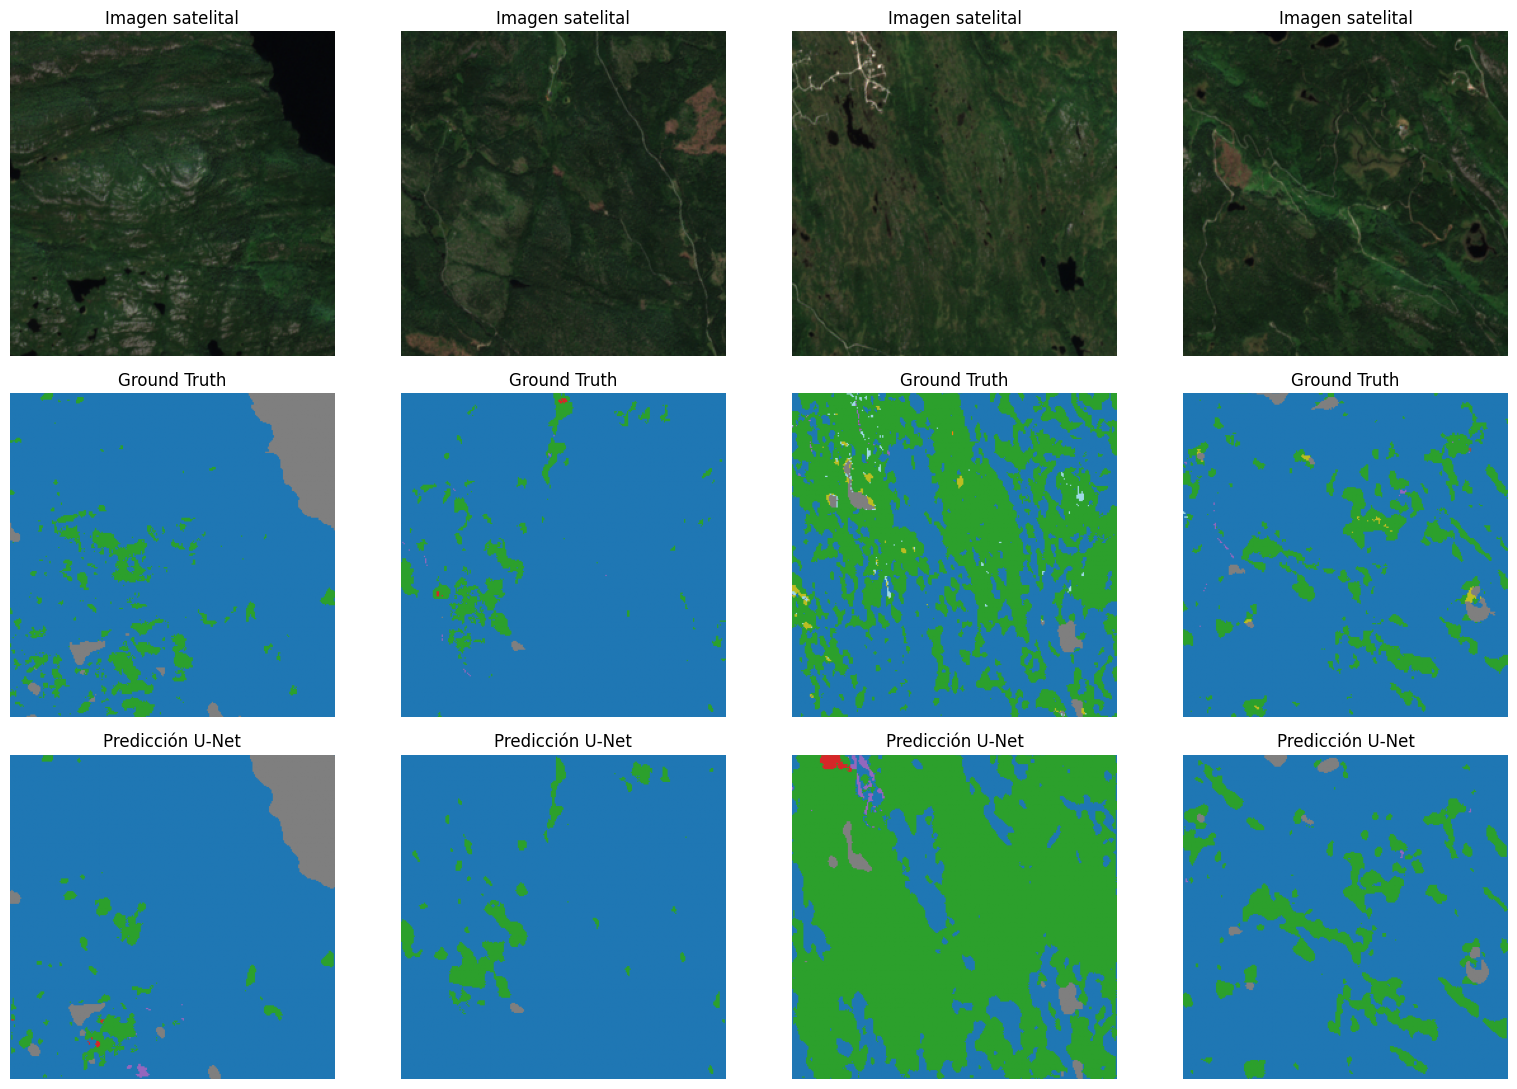

In [20]:
imgs, masks = next(iter(val_loader))
imgs_div = imgs.to(DEVICE)

modelo.eval()
with torch.no_grad():
    preds = modelo(imgs_div).argmax(dim=1).cpu()
    
fig, axs = plt.subplots(3, 4, figsize=(16, 11))

for i in range(4):
    axs[0, i].imshow(imgs[i].permute(1, 2, 0).cpu().numpy())
    axs[0, i].set_title("Imagen satelital")
    axs[0, i].axis("off")

    axs[1, i].imshow(masks[i].cpu().numpy(), cmap="tab20", vmin=0, vmax=10)
    axs[1, i].set_title("Ground Truth")
    axs[1, i].axis("off")

    axs[2, i].imshow(preds[i].numpy(), cmap="tab20", vmin=0, vmax=10)
    axs[2, i].set_title("Predicción U-Net")
    axs[2, i].axis("off")

plt.tight_layout()
plt.show()

In [21]:
print(torch.manual_seed)
print(type(torch.manual_seed))

<function manual_seed at 0x788c44e1cfe0>
<class 'function'>


In [22]:
results_yolo = model_yolo.train(
    data=str(YOLO_DATA_DIR / "dataset.yaml"),
    epochs=EPOCHS,
    imgsz=256,
    batch=BATCH_SIZE,
    device=0,
    workers=0,
    project="runs/satellite",
    name="yolo26n_sem",
    exist_ok=True,
    plots=False
)

Ultralytics 8.4.220 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/root/data/SatelliteSegmentation_YOLO/dataset.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=256, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n-sem.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo26n_sem, nbs=64, nms=None, opse

In [26]:
model_yolo_test = YOLO("runs/semantic/runs/satellite/yolo26n_sem/weights/best.pt")
model_yolo_test.eval()
with torch.no_grad():
    for images, masks in val_loader:
        preds = []
        for image in images:
            #YOLO lee [B,H,W] :p
            image_np = image.permute(1,2,0).numpy()
            image_np = (image_np * 255).clip(0,255).astype(np.uint8)

            image_bgr = cv2.cvtColor(image_np, cv2.COLOR_RGB2BGR)
            result= model_yolo_test.predict(source=image_bgr, imgsz=256, device=0, verbose=False)[0]
            pred = result.semantic_mask.data
            preds.append(pred.cpu())

        preds = torch.stack(preds).to(DEVICE)
        masks = masks.to(DEVICE)
        metric_iou.update(preds, masks)
        metric_dice.update(preds, masks)

iou_per_class = metric_iou.compute().cpu().numpy()
dice_per_class = metric_dice.compute().cpu().numpy()

miou = np.nanmean(iou_per_class)
mdice = np.nanmean(dice_per_class)

print(f"mIoU YOLO: {miou:.4f}")
print(f"mDice YOLO: {mdice:.4f}")


mIoU YOLO: 0.3291
mDice YOLO: 0.3887


In [27]:
results_test_yolo = pd.DataFrame({
    "Clase": [model_class_names[i] for i in range(11)],
    "IoU": iou_per_class,
    "Dice": dice_per_class
})

display(results_test_yolo)

print(f"mIoU: {miou:.4f}")
print(f"mDice: {mdice:.4f}")

results_test_yolo.to_csv(
    "results_test_yolo.csv",
    index=False
)

pd.DataFrame({
    "Metric": ["mIoU", "mDice"],
    "Value": [miou, mdice]
}).to_csv(
    "summary_test_yolo.csv",
    index=False
)

,Clase,IoU,Dice
0,Árboles,0.329129,0.388727
1,Matorrales,0.329129,0.388727
2,Pastizales,0.329129,0.388727
3,Cultivos,0.329129,0.388727
4,Zonas construidas,0.329129,0.388727
5,Suelo desnudo / vegetación escasa,0.329129,0.388727
6,Nieve y hielo,0.329129,0.388727
7,Cuerpos de agua,0.329129,0.388727
8,Humedales,0.329129,0.388727
9,Manglares,0.329129,0.388727


mIoU: 0.3291
mDice: 0.3887


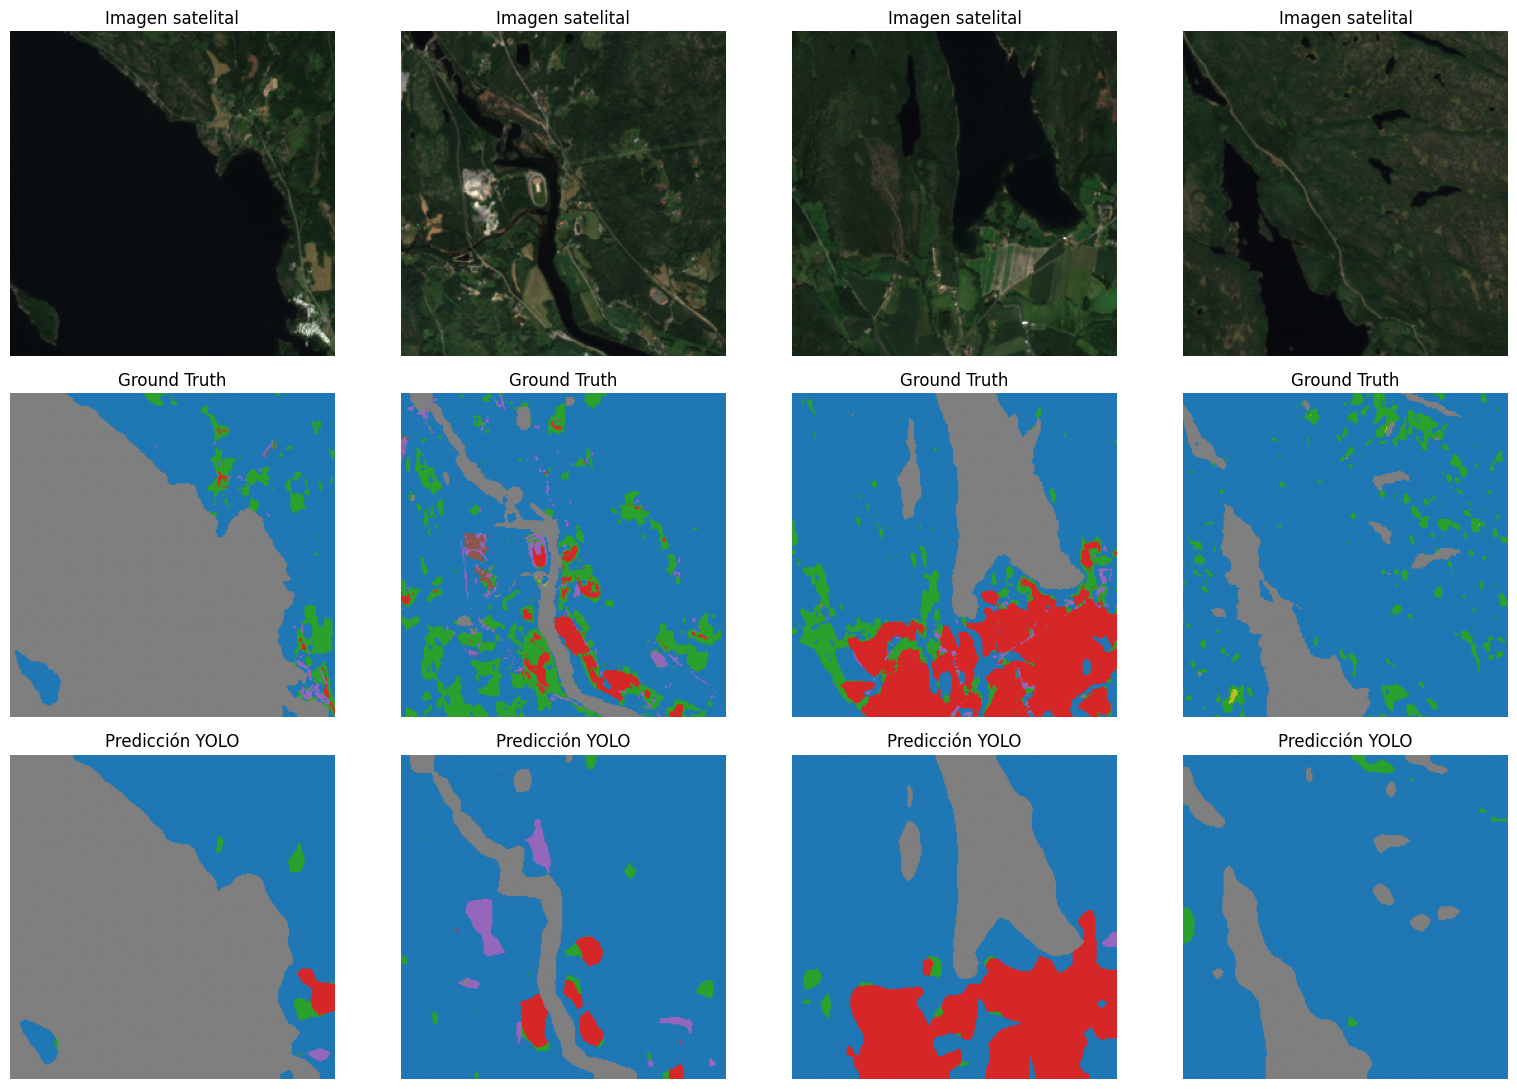

In [28]:
imgs, masks = next(iter(test_loader))
preds_yolo = []
model_yolo_test.eval()

with torch.no_grad():
    for image in imgs:
        image_np = image.permute(1, 2, 0).numpy()
        image_np = (image_np * 255).clip(0, 255).astype(np.uint8)

        image_bgr = cv2.cvtColor(image_np, cv2.COLOR_RGB2BGR)

        result = model_yolo_test.predict(
            source=image_bgr,
            imgsz=256,
            device=0,
            verbose=False)[0]

        pred = result.semantic_mask.data.cpu().numpy()
        preds_yolo.append(pred)

preds_yolo = np.stack(preds_yolo)
fig, axs = plt.subplots(3, 4, figsize=(16, 11))
for i in range(4):

    axs[0, i].imshow(imgs[i].permute(1, 2, 0).cpu().numpy())
    axs[0, i].set_title("Imagen satelital")
    axs[0, i].axis("off")

    axs[1, i].imshow(masks[i].numpy(), cmap="tab20", vmin=0, vmax=10)
    axs[1, i].set_title("Ground Truth")
    axs[1, i].axis("off")

    axs[2, i].imshow(preds_yolo[i], cmap="tab20", vmin=0, vmax=10)
    axs[2, i].set_title("Predicción YOLO")
    axs[2, i].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
class DiceLoss(nn.Module):
    def __init__(self, eps=1e-6):
        super().__init__()
        self.eps = eps

    def forward(self, logits, targets):
        num_classes = logits.shape[1]
        probs = F.softmax(logits, dim=1)

        # One-hot encoding de targets a dimensiones [B, C, H, W]
        targets_one_hot = F.one_hot(targets, num_classes=num_classes).permute(0, 3, 1, 2).float()

        # Aplanar dimensiones espaciales para el cálculo vectorial
        probs = probs.contiguous().view(probs.shape[0], num_classes, -1)
        targets_one_hot = targets_one_hot.contiguous().view(targets_one_hot.shape[0], num_classes, -1)

        interseccion = (probs * targets_one_hot).sum(dim=2)
        union = probs.sum(dim=2) + targets_one_hot.sum(dim=2)

        dice = (2. * interseccion + self.eps) / (union + self.eps)
        return 1.0 - dice.mean()

# Instanciación de pérdidas
ce_fn = nn.CrossEntropyLoss()
dice_fn = DiceLoss()

def loss_combinada(logits, targets):
    return ce_fn(logits, targets) + dice_fn(logits, targets)